In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")    
plt.rcParams['figure.figsize'] = (12, 6)



In [57]:
df = pd.read_csv("student_performance_informatika.csv")

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   attendance_pct       800 non-null    float64
 1   study_hours_week     800 non-null    float64
 2   sleep_hours          800 non-null    float64
 3   screen_time_hours    800 non-null    float64
 4   parttime_hours_week  800 non-null    int64  
 5   commute_minutes      800 non-null    int64  
 6   internet_quality     800 non-null    int64  
 7   org_activity         800 non-null    int64  
 8   hs_math_score        800 non-null    int64  
 9   assignment_avg       800 non-null    float64
 10  quiz_avg             800 non-null    float64
 11  midterm_score        800 non-null    float64
 12  Year                 800 non-null    int64  
 13  passed               800 non-null    int64  
dtypes: float64(7), int64(7)
memory usage: 87.6 KB


In [59]:
df.shape

(800, 14)

In [60]:
df.head()

,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year,passed
0,75.2,8.9,6.8,1.0,0,28,4,2,82,74.0,63.5,76.6,2024,1
1,74.3,6.7,4.2,1.7,0,37,3,0,100,64.2,62.4,63.1,2024,1
2,84.1,11.9,7.7,2.2,0,13,4,2,72,73.2,71.1,41.3,2024,1
3,74.4,4.8,6.6,3.7,6,15,3,1,61,42.3,49.5,76.0,2024,0
4,100.0,7.5,6.4,2.2,0,30,4,2,70,66.7,51.9,71.4,2024,1


In [61]:
df.tail()

,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year,passed
795,71.6,5.9,8.8,2.0,0,10,3,1,73,59.8,45.8,72.4,2018,0
796,81.8,4.3,7.1,6.5,0,8,3,1,54,43.7,36.2,55.7,2018,0
797,94.5,6.4,6.0,5.8,11,24,4,1,66,64.4,60.5,71.2,2018,1
798,85.0,2.2,6.1,3.8,0,23,3,0,75,68.6,69.2,80.9,2018,1
799,79.9,4.4,7.2,4.3,0,31,2,1,73,58.7,39.4,65.3,2018,0


In [62]:
df.isnull().sum()

attendance_pct         0
study_hours_week       0
sleep_hours            0
screen_time_hours      0
parttime_hours_week    0
commute_minutes        0
internet_quality       0
org_activity           0
hs_math_score          0
assignment_avg         0
quiz_avg               0
midterm_score          0
Year                   0
passed                 0
dtype: int64

In [63]:
df.duplicated().sum()

np.int64(0)

In [64]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
attendance_pct,800.0,84.613250,10.269008,54.8,77.25,84.70,92.800,100.0
study_hours_week,800.0,6.554125,3.871608,0.8,3.70,5.75,8.325,21.9
sleep_hours,800.0,6.396875,1.086798,3.4,5.60,6.40,7.100,9.9
screen_time_hours,800.0,4.055750,2.159977,1.0,2.40,3.70,5.300,13.5
parttime_hours_week,800.0,5.090000,8.785977,0.0,0.00,0.00,8.250,29.0
commute_minutes,800.0,30.398750,19.174249,2.0,17.00,26.00,40.000,136.0
internet_quality,800.0,3.312500,0.931896,1.0,3.00,3.00,4.000,5.0
org_activity,800.0,0.903750,0.907202,0.0,0.00,1.00,1.000,3.0
hs_math_score,800.0,72.720000,11.293517,35.0,65.00,73.00,80.000,100.0
assignment_avg,800.0,67.740875,10.635872,40.3,60.10,67.40,74.325,100.0


In [65]:
data = df.columns.to_list()

In [66]:
for col in data:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1 
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 *  IQR

    
    df[col] = np.where(df[col] < lower_bound , lower_bound,
              np.where(df[col] > upper_bound, upper_bound, df[col]))

    print(f"""COLOMNS : {col}
            Q1 : {Q1}
            Q3 : {Q3}
            IQR : {IQR}
        LOWER BOUND : {lower_bound}
        UPPER BOUND : {upper_bound}
    """)





COLOMNS : attendance_pct
            Q1 : 77.25
            Q3 : 92.8
            IQR : 15.549999999999997
        LOWER BOUND : 53.925000000000004
        UPPER BOUND : 116.125
    
COLOMNS : study_hours_week
            Q1 : 3.7
            Q3 : 8.325000000000001
            IQR : 4.625000000000001
        LOWER BOUND : -3.2375000000000016
        UPPER BOUND : 15.262500000000003
    
COLOMNS : sleep_hours
            Q1 : 5.6
            Q3 : 7.1
            IQR : 1.5
        LOWER BOUND : 3.3499999999999996
        UPPER BOUND : 9.35
    
COLOMNS : screen_time_hours
            Q1 : 2.4
            Q3 : 5.3
            IQR : 2.9
        LOWER BOUND : -1.9499999999999997
        UPPER BOUND : 9.649999999999999
    
COLOMNS : parttime_hours_week
            Q1 : 0.0
            Q3 : 8.25
            IQR : 8.25
        LOWER BOUND : -12.375
        UPPER BOUND : 20.625
    
COLOMNS : commute_minutes
            Q1 : 17.0
            Q3 : 40.0
            IQR : 23.0
        LOWER BOUND

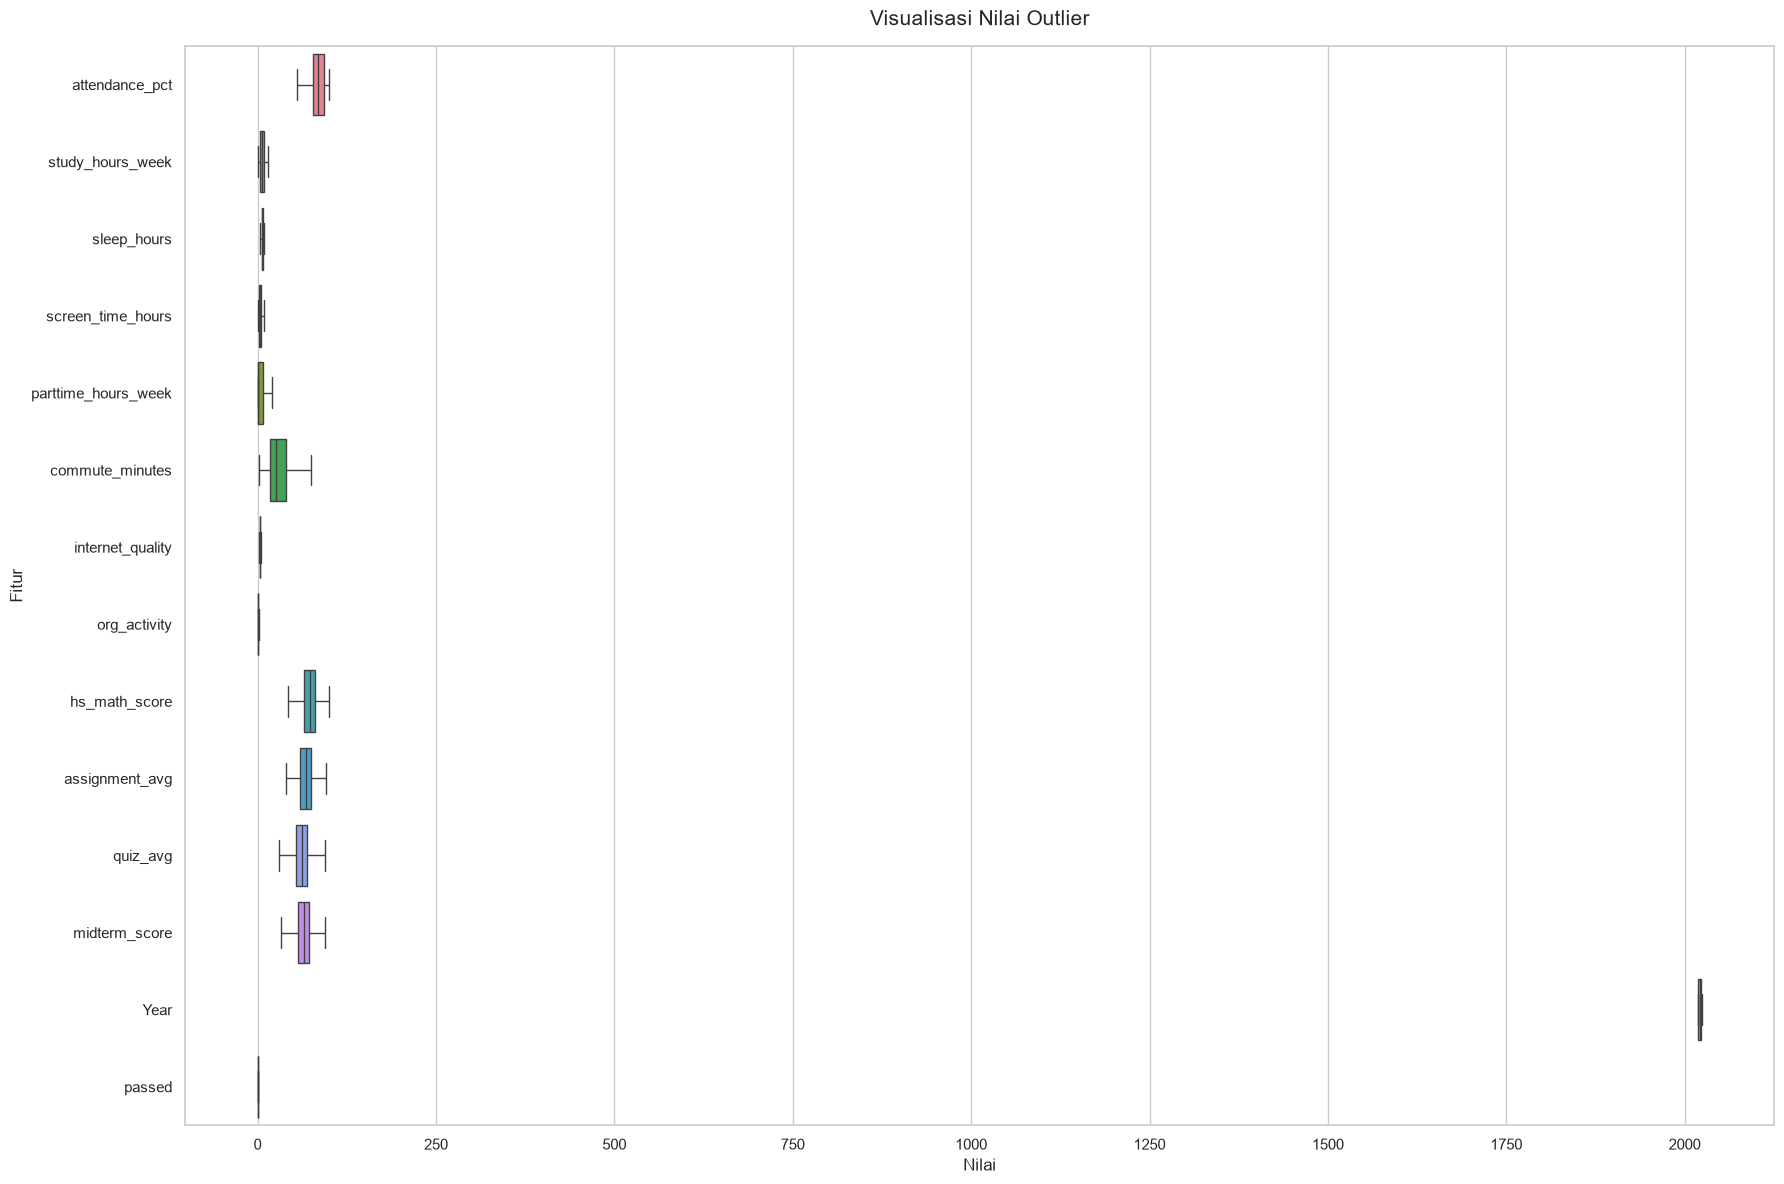

BERIKUT DATA OUTLIER SETELAH DI BUAT LEBIH RAPIH (AFTER DI CAPPING)


In [67]:

plt.figure(figsize=(18,12))
sns.boxplot(data=df[data], orient='h')
plt.title("Visualisasi Nilai Outlier", fontsize=15, pad=15)
plt.xlabel("Nilai" , fontsize=12)
plt.ylabel("Fitur", fontsize=12)

plt.tight_layout()
plt.show()

print("berikut data outlier setelah di buat lebih rapih (after di capping)".upper())

<Axes: >

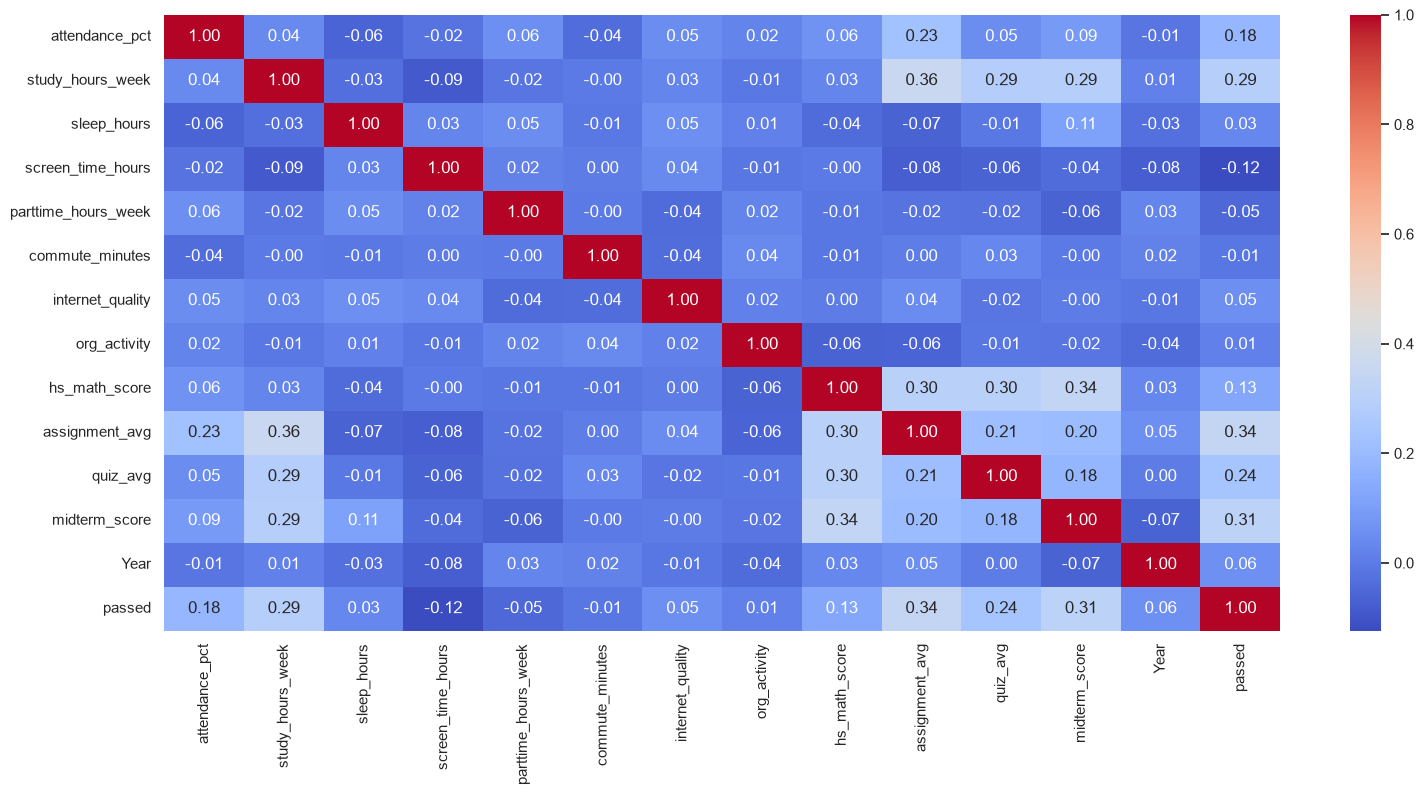

In [68]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(18,8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

In [69]:
data = df[[
    'attendance_pct',
    'study_hours_week',
    'hs_math_score',
    'assignment_avg',
    'quiz_avg',
    'midterm_score'
]].columns.to_list()

In [70]:
x = df[[
    'attendance_pct',
    'study_hours_week',
    'hs_math_score',
    'assignment_avg',
    'quiz_avg',
    'midterm_score'
]]
y = df["passed"]

In [71]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Data Training {X_train.shape}")
print(f"Data Testing {X_test.shape}")


Data Training (640, 6)
Data Testing (160, 6)


In [72]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num' , StandardScaler(), data),
    ],
remainder='passthrough'
)

In [73]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. 

In [79]:
models = {
    "Logistic Regression" : LogisticRegression(),
    " Random Forest " : RandomForestClassifier(),
    " Decision Tree" : DecisionTreeClassifier(), 
    'svm' : SVC(),
    'Knn' : KNeighborsClassifier()
    
}

In [80]:
result_list = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprosescor', preprocessor ),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:,1] if hasattr(pipeline, "predict_proba") else None

    acc = accuracy_score(y_pred,y_test)
    prec = precision_score(y_pred, y_test)
    rec = recall_score(y_pred, y_test)
    f1 = f1_score(y_pred, y_test)
    roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.False_

    result_list.append({
        'model' : name,
        'accuracy' : acc,
        'precision' : prec,
        'recall' : rec,
        'f1-score' : f1,
        'roc_auc' : roc_auc
    })

df_results = pd.DataFrame(result_list).sort_values(by='f1-score',ascending=False).reset_index(drop=True)

df_results


,model,accuracy,precision,recall,f1-score,roc_auc
0,svm,0.69375,0.728261,0.736264,0.732240,False
1,Logistic Regression,0.67500,0.695652,0.727273,0.711111,0.728101
2,Random Forest,0.66875,0.695652,0.719101,0.707182,0.712756
3,Decision Tree,0.63125,0.706522,0.670103,0.687831,0.617967
4,Knn,0.58750,0.630435,0.644444,0.637363,0.657928
